,max_depth,train_accuracy,test_accuracy
0,1,0.666667,0.666667
1,2,0.966667,0.933333
2,3,0.983333,0.966667
3,4,0.991667,0.933333
4,5,1.000000,0.933333
5,None,1.000000,0.933333


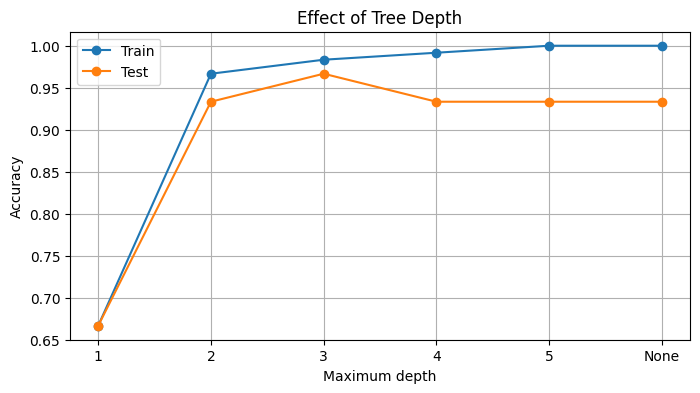

Test accuracy: 0.9666666666666667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



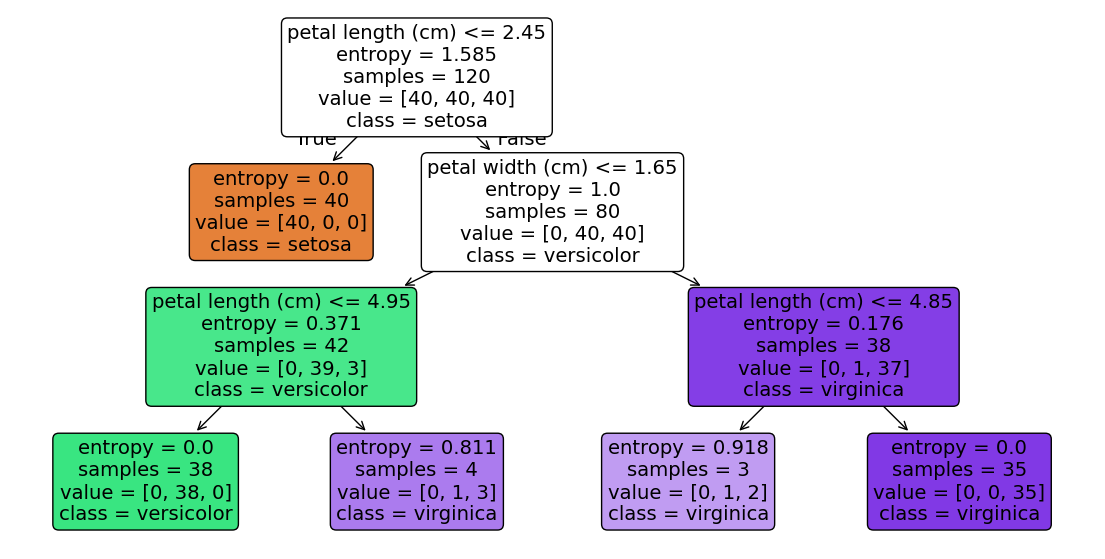

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

depths = [1,2,3,4,5,None]
rows = []
for depth in depths:
    clf = DecisionTreeClassifier(max_depth=depth, criterion="gini", random_state=42)
    clf.fit(X_train, y_train)
    rows.append({
        "max_depth": str(depth),
        "train_accuracy": accuracy_score(y_train, clf.predict(X_train)),
        "test_accuracy": accuracy_score(y_test, clf.predict(X_test))
    })
results = pd.DataFrame(rows)
display(results)

plt.figure(figsize=(8,4))
plt.plot(results["max_depth"], results["train_accuracy"], marker="o", label="Train")
plt.plot(results["max_depth"], results["test_accuracy"], marker="o", label="Test")
plt.xlabel("Maximum depth")
plt.ylabel("Accuracy")
plt.title("Effect of Tree Depth")
plt.legend()
plt.grid()
plt.show()

tree = DecisionTreeClassifier(max_depth=3, criterion="entropy", random_state=42)
tree.fit(X_train, y_train)
pred = tree.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred, target_names=iris.target_names))

plt.figure(figsize=(14,7))
plot_tree(tree, feature_names=iris.feature_names,
          class_names=iris.target_names, filled=True, rounded=True)
plt.show()